# Recovering the FIJI crop + display range (min/max) used for the SPARK example strips

The PNG frames in `ikk-spk-1/`, `ikk-spk-novel/`, `tbk1-spk-1/`, `tbk1-spk-novel/`, `tbk1-spk-novel-2/` (plotted in `Untitled.ipynb`)
were exported from FIJI after **cropping** and **setting the display range (B&C min/max)**, with a green or gray LUT and a
flattened time-stamp + scale-bar overlay. The PNGs carry no metadata, so the parameters are recovered here by fitting.

**ImageJ 16-bit → 8-bit rule** (`ShortProcessor.create8BitImage`):
`out = min(255, int( max(raw - min, 0) * 256/(max - min + 1) + 0.5 ))`. For the green LUT, the 8-bit value is the **G channel** of the PNG.

Two recovery strategies:
* **A. Raw stack available locally** → template-match the crop, then grid-search integer (min, max) for an *exact* pixel match.
* **B. Raw stack not available** (`${SPARK_ACQUISITION_MOUNT}` is not mounted here) → use the CellSAM masks + per-cell `cell_total_int` stored in
  `spark_results.h5`. Since `png = k·(raw − min)`, summing over a cell gives `Σpng = k·total_int − k·min·area`; a regression over
  cells × frames gives `k` and `min`. Validated on `tbk1-spk-1`, where the answer is known from A.

### Result summary (filled in by the cells below)

| example folder | source stack | crop (x, y, w, h) | min | max | method / confidence |
|---|---|---|---|---|---|
| `tbk1-spk-1` | `C2-240731_plate2c1xy62.tif` | (396, 806, 694, 694) | **119** | **7152** | A — exact (99.9 % pixels identical; rest = overlay) |
| `ikk-spk-novel` | `20240822_cy_plate2c1xy48` (`X.ome.tiff` in zip) | (442, 578, 492, 492) | **137** | **1150** | A — exact (99.5 % identical; rest = overlay) |
| `tbk1-spk-novel-2` | `240731_plate3c1xy40.tif` | (995, 574, 524, 524) | **≈104** (95% CI 104–105) | **≈5567** (5564–5570) | B — good (fit residual 0.02 %) |
| `tbk1-spk-novel` | `240731_plate3c1xy65.tif` | (133, 296, 623, 623) | **≈97** (95% CI 87–104) | **≈6965** (6907–7044) | B — approximate (saturated pixels, few clean cells; residual 0.34 %) |
| `ikk-spk-1` | `20240822_cy_plate2c1xy13.tif` (IKK-SPK-1 / TNFa) | (128, 1176, 433, 432) | **119 / 115 / 117 / 116** | **2639 / 4403 / 7328 / 9546** | A — exact, but **display range changes in 4 blocks**: frames 0–27, 28–34, 35–42, 43–60 (99.4–99.5 % identical per frame) |

All folders use one crop for every frame. All but `ikk-spk-1` also use one min/max for the whole stack; `ikk-spk-1` had its B&C max raised three times during the movie (each new max ≈ the brightest crop pixel of a recent frame, e.g. 2639 = max of frame 19, 4403 = max of frame 27, 7328 = max of frame 36) so the brightening cell would not saturate.

In [1]:
import glob, io, os, zipfile
import numpy as np
import pandas as pd
import cv2, tifffile, h5py
import matplotlib.pyplot as plt
from PIL import Image

HERE = os.path.abspath('.')   # run from cellsam-internal/spark_examples
H5 = 'spark_results.h5'

def ij_to_8bit(raw, mn, mx):
    '''Exact ImageJ 16-bit -> 8-bit conversion with display range [mn, mx].'''
    v = np.clip(raw.astype(np.float64) - mn, 0, None)
    return np.minimum((v * (256.0 / (mx - mn + 1)) + 0.5).astype(np.int64), 255).astype(np.uint8)

def green_lut(img8):
    '''Apply FIJI 'Green' LUT -> RGB.'''
    out = np.zeros(img8.shape + (3,), np.uint8); out[..., 1] = img8; return out

def load_png_value(fn):
    '''8-bit intensity of an exported frame (G channel works for both Green and Grays LUT).'''
    return np.array(Image.open(fn).convert('RGB'))[..., 1]

def png_files(folder):
    return sorted(glob.glob(os.path.join(folder, '*.png')))

def read_X_from_zip(zip_path):
    with zipfile.ZipFile(zip_path) as zf, zf.open('X.ome.tiff') as fh:
        return tifffile.imread(io.BytesIO(fh.read()))

def locate_crop(frame, png):
    res = cv2.matchTemplate(frame.astype(np.float32), png.astype(np.float32), cv2.TM_CCOEFF_NORMED)
    _, cc, _, (x, y) = cv2.minMaxLoc(res)
    return x, y, cc

## A. Exact recovery from the raw stack

`fit_display_range` first gets a linear least-squares estimate (ignoring 0/255 pixels), then grid-searches integer (min, max)
around it for the highest fraction of exactly-matching pixels. Overlay pixels (time stamp, scale bar) never match, so ~99.5–99.9 % is perfect.

In [2]:
def fit_display_range(crop, png, n_sample=150_000, seed=0):
    crop = crop.astype(np.int64); png = png.astype(np.int64)
    m = (png > 0) & (png < 250)
    a, b = np.polyfit(crop[m], png[m], 1)
    mn0 = -b / a; mx0 = mn0 + 256 / a - 1
    idx = np.random.default_rng(seed).choice(crop.size, min(n_sample, crop.size), replace=False)
    cv, pv = crop.ravel()[idx], png.ravel()[idx]
    best = (-1, None)
    for mn in range(int(mn0) - 6, int(mn0) + 7):
        for mx in range(int(mx0) - 60, int(mx0) + 61):
            acc = (ij_to_8bit(cv, mn, mx) == pv).mean()
            if acc > best[0]:
                best = (acc, (mn, mx))
    return best[1], (mn0, mx0)

def recover_from_raw(stack, folder, check_frames=(0, 10, 30, 60)):
    files = png_files(folder)
    png0 = load_png_value(files[0]); h, w = png0.shape
    x, y, cc = locate_crop(stack[0], png0)
    (mn, mx), lin = fit_display_range(stack[0, y:y+h, x:x+w], png0)
    print(f'{folder}: crop x={x} y={y} w={w} h={h} (cc={cc:.3f}); linear est min={lin[0]:.1f} max={lin[1]:.1f} -> exact min={mn} max={mx}')
    for t in check_frames:
        p = load_png_value(files[t])
        pred = ij_to_8bit(stack[t, y:y+h, x:x+w], mn, mx)
        print(f'   frame {t:02d}: identical pixels {np.mean(pred == p)*100:.2f} %')
    return dict(x=x, y=y, w=w, h=h, min=mn, max=mx)

In [3]:
raw_xy62 = tifffile.imread('C2-240731_plate2c1xy62.tif')
with tifffile.TiffFile('C2-240731_plate2c1xy62.tif') as t:
    print('ImageJ header of the tif (display range when the *tif* was saved, NOT the one used for the PNGs):',
          {k: t.imagej_metadata[k] for k in ('min', 'max')})
params = {}
params['tbk1-spk-1'] = recover_from_raw(raw_xy62, 'tbk1-spk-1')

ImageJ header of the tif (display range when the *tif* was saved, NOT the one used for the PNGs): {'min': 101.0, 'max': 5740.0}


tbk1-spk-1: crop x=396 y=806 w=694 h=694 (cc=0.812); linear est min=119.2 max=7151.8 -> exact min=119 max=7152
   frame 00: identical pixels 99.93 %
   frame 10: identical pixels 99.91 %
   frame 30: identical pixels 99.89 %
   frame 60: identical pixels 99.89 %


In [4]:
raw_xy48 = read_X_from_zip('20240822_cy_plate2c1xy48.zip')   # float32 copy of the raw uint16 values
print(raw_xy48.shape, raw_xy48.dtype, 'integer valued:', bool(np.all(raw_xy48[0] == np.round(raw_xy48[0]))))
params['ikk-spk-novel'] = recover_from_raw(raw_xy48, 'ikk-spk-novel')

(61, 1608, 1608) float32 integer valued: True


ikk-spk-novel: crop x=442 y=578 w=492 h=492 (cc=0.902); linear est min=136.0 max=1151.5 -> exact min=137 max=1150
   frame 00: identical pixels 99.59 %
   frame 10: identical pixels 99.55 %
   frame 30: identical pixels 99.53 %
   frame 60: identical pixels 99.52 %


## B. Recovery without raw pixels: CellSAM masks + per-cell integrated intensity (`spark_results.h5`)

For every (frame, cell) whose mask lies completely inside the crop, away from the overlay corners, and has no clipped (0/255) pixels:
`Σ png = k·cell_total_int − k·min·cell_area_px`. Least squares gives `k`, `min`; then `max = min + 256/k − 1`.
The crop offset from mask-vs-PNG template matching can be off by a pixel or two, so it is refined by minimising the fit residual.

In [5]:
def recover_from_masks(run, folder, search=3, verbose=True):
    g = h5py.File(H5, 'r')[run]
    df = {c: g['spark_df'][c][()] for c in g['spark_df']}
    files = png_files(folder)
    pngs = [np.array(Image.open(f).convert('RGB')) for f in files]
    masks = g['tracked_masks'][()]
    h, w = pngs[0].shape[:2]
    x0, y0, cc = locate_crop((masks[0] > 0).astype(np.float32), pngs[0][..., 1])
    ov = np.zeros((h, w), bool); ov[:int(.08*h), :int(.3*w)] = True; ov[int(.88*h):, int(.7*w):] = True  # time stamp / scale bar

    def collect(x, y, frames):
        rows = []
        for t in frames:
            G = pngs[t][..., 1].astype(float); Mc = masks[t, y:y+h, x:x+w]
            sel = df['frame'] == t
            for cid, tot, area in zip(df['cell_id'][sel], df['cell_total_int'][sel], df['cell_area_px'][sel]):
                ins = Mc == cid
                if area == 0 or ins.sum() != area or (ins & ov).any(): continue
                if (G[ins] >= 255).any() or (G[ins] <= 0).mean() > 0.01: continue
                rows.append((G[ins].sum(), tot, area))
        return np.array(rows)

    def solve(r):
        A = np.c_[r[:, 1], r[:, 2]]
        (k, c), *_ = np.linalg.lstsq(A, r[:, 0], rcond=None)
        return k, c, np.median(np.abs(A @ [k, c] - r[:, 0]) / r[:, 0])

    best = None
    for dx in range(-search, search + 1):
        for dy in range(-search, search + 1):
            r = collect(x0 + dx, y0 + dy, range(0, len(files), 6))
            if len(r) < 3: continue
            e = solve(r)[2]
            if best is None or e < best[0]: best = (e, x0 + dx, y0 + dy)
    x, y = best[1], best[2]
    rows = collect(x, y, range(len(files)))
    k, c, err = solve(rows)
    mn = -c / k; mx = mn + 256 / k - 1
    # bootstrap over (cell, frame) rows for an uncertainty estimate
    rng = np.random.default_rng(0); bs = []
    for _ in range(500):
        kk, cc_, _ = solve(rows[rng.integers(0, len(rows), len(rows))]); bs.append((-cc_/kk, -cc_/kk + 256/kk - 1))
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    if verbose:
        print(f'{run} -> {folder}: crop x={x} y={y} w={w} h={h}; n={len(rows)} cell-frames; median rel. residual {err*100:.3f} %')
        print(f'   min = {mn:.1f}  (95% CI {lo[0]:.0f}–{hi[0]:.0f})   max = {mx:.1f}  (95% CI {lo[1]:.0f}–{hi[1]:.0f})')
    return dict(x=x, y=y, w=w, h=h, min=mn, max=mx, resid=err, ci_min=(lo[0], hi[0]), ci_max=(lo[1], hi[1]))

**Validation** on `tbk1-spk-1` (truth from section A: min 119, max 7152):

In [6]:
_ = recover_from_masks('0731p2-62', 'tbk1-spk-1')

0731p2-62 -> tbk1-spk-1: crop x=396 y=806 w=694 h=694; n=62 cell-frames; median rel. residual 0.010 %
   min = 119.1  (95% CI 119–119)   max = 7152.4  (95% CI 7152–7160)


In [7]:
params['tbk1-spk-novel-2'] = recover_from_masks('0731p3-40', 'tbk1-spk-novel-2')
params['tbk1-spk-novel']   = recover_from_masks('0731p3-65', 'tbk1-spk-novel')

0731p3-40 -> tbk1-spk-novel-2: crop x=995 y=574 w=524 h=524; n=30 cell-frames; median rel. residual 0.020 %
   min = 104.4  (95% CI 104–105)   max = 5566.7  (95% CI 5564–5570)


0731p3-65 -> tbk1-spk-novel: crop x=133 y=296 w=623 h=623; n=18 cell-frames; median rel. residual 0.343 %
   min = 96.6  (95% CI 87–104)   max = 6964.8  (95% CI 6907–7044)


`tbk1-spk-novel` (xy65) is the weakest estimate: the bright cell has up to ~140 saturated (255) pixels in most frames, so only a handful of
(frame, cell) rows are usable and the residual is 0.34 % (vs 0.01–0.02 % for the others). Treat min≈97 / max≈6965 as approximate and re-run
`recover_from_raw` once `${SPARK_ACQUISITION_ROOT}/ExRai-imaging/240731_plate3/240731_plate3c1xy65.tif` is accessible.

`ikk-spk-1` (`frame_0001..0061.png`, 432×433, gray LUT) did not match any local stack (all 15 zips' `X.ome.tiff` and all 22 runs in
`spark_results.h5` give template correlation ≤ 0.6, vs 0.8–0.9 for true matches) and the odd 432×433 size suggests it was also rescaled,
so its parameters cannot be recovered from the data on this machine.

## C. Re-create the FIJI-normalised frames in Python

`normalize_like_fiji` crops and applies the ImageJ display-range conversion (optionally with the green LUT). It needs the raw stack,
so it runs here for the two stacks available locally; for xy40/xy65 point `RAW_PATHS` at the madrox tifs when mounted.
Outputs (no time-stamp / scale-bar overlay) go to `python_normalized/<folder>/`.

In [8]:
def normalize_like_fiji(stack, p, lut='green'):
    crop = stack[:, p['y']:p['y']+p['h'], p['x']:p['x']+p['w']]
    img8 = ij_to_8bit(crop, round(p['min']), round(p['max']))
    return green_lut(img8) if lut == 'green' else img8

RAW_PATHS = {
    'tbk1-spk-1':       'C2-240731_plate2c1xy62.tif',
    'ikk-spk-novel':    ('zip', '20240822_cy_plate2c1xy48.zip'),
    'tbk1-spk-novel-2': '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/240731_plate3/240731_plate3c1xy40.tif',
    'tbk1-spk-novel':   '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/240731_plate3/240731_plate3c1xy65.tif',
}
def load_raw(src):
    if isinstance(src, tuple): return read_X_from_zip(src[1])
    return tifffile.imread(src)

stacks = {'tbk1-spk-1': raw_xy62, 'ikk-spk-novel': raw_xy48}
for name, src in RAW_PATHS.items():
    if name not in stacks and not isinstance(src, tuple) and os.path.exists(src):
        stacks[name] = load_raw(src)

SAVE = True
for name, stack in stacks.items():
    rgb = normalize_like_fiji(stack, params[name])
    if SAVE:
        out = os.path.join('python_normalized', name); os.makedirs(out, exist_ok=True)
        for t, fr in enumerate(rgb):
            Image.fromarray(fr).save(os.path.join(out, f'{name}_{t:02d}.png'))
    print(name, '->', rgb.shape, 'params', {k: params[name][k] for k in ('x', 'y', 'w', 'h', 'min', 'max')})

tbk1-spk-1 -> (61, 694, 694, 3) params {'x': 396, 'y': 806, 'w': 694, 'h': 694, 'min': 119, 'max': 7152}


ikk-spk-novel -> (61, 492, 492, 3) params {'x': 442, 'y': 578, 'w': 492, 'h': 492, 'min': 137, 'max': 1150}


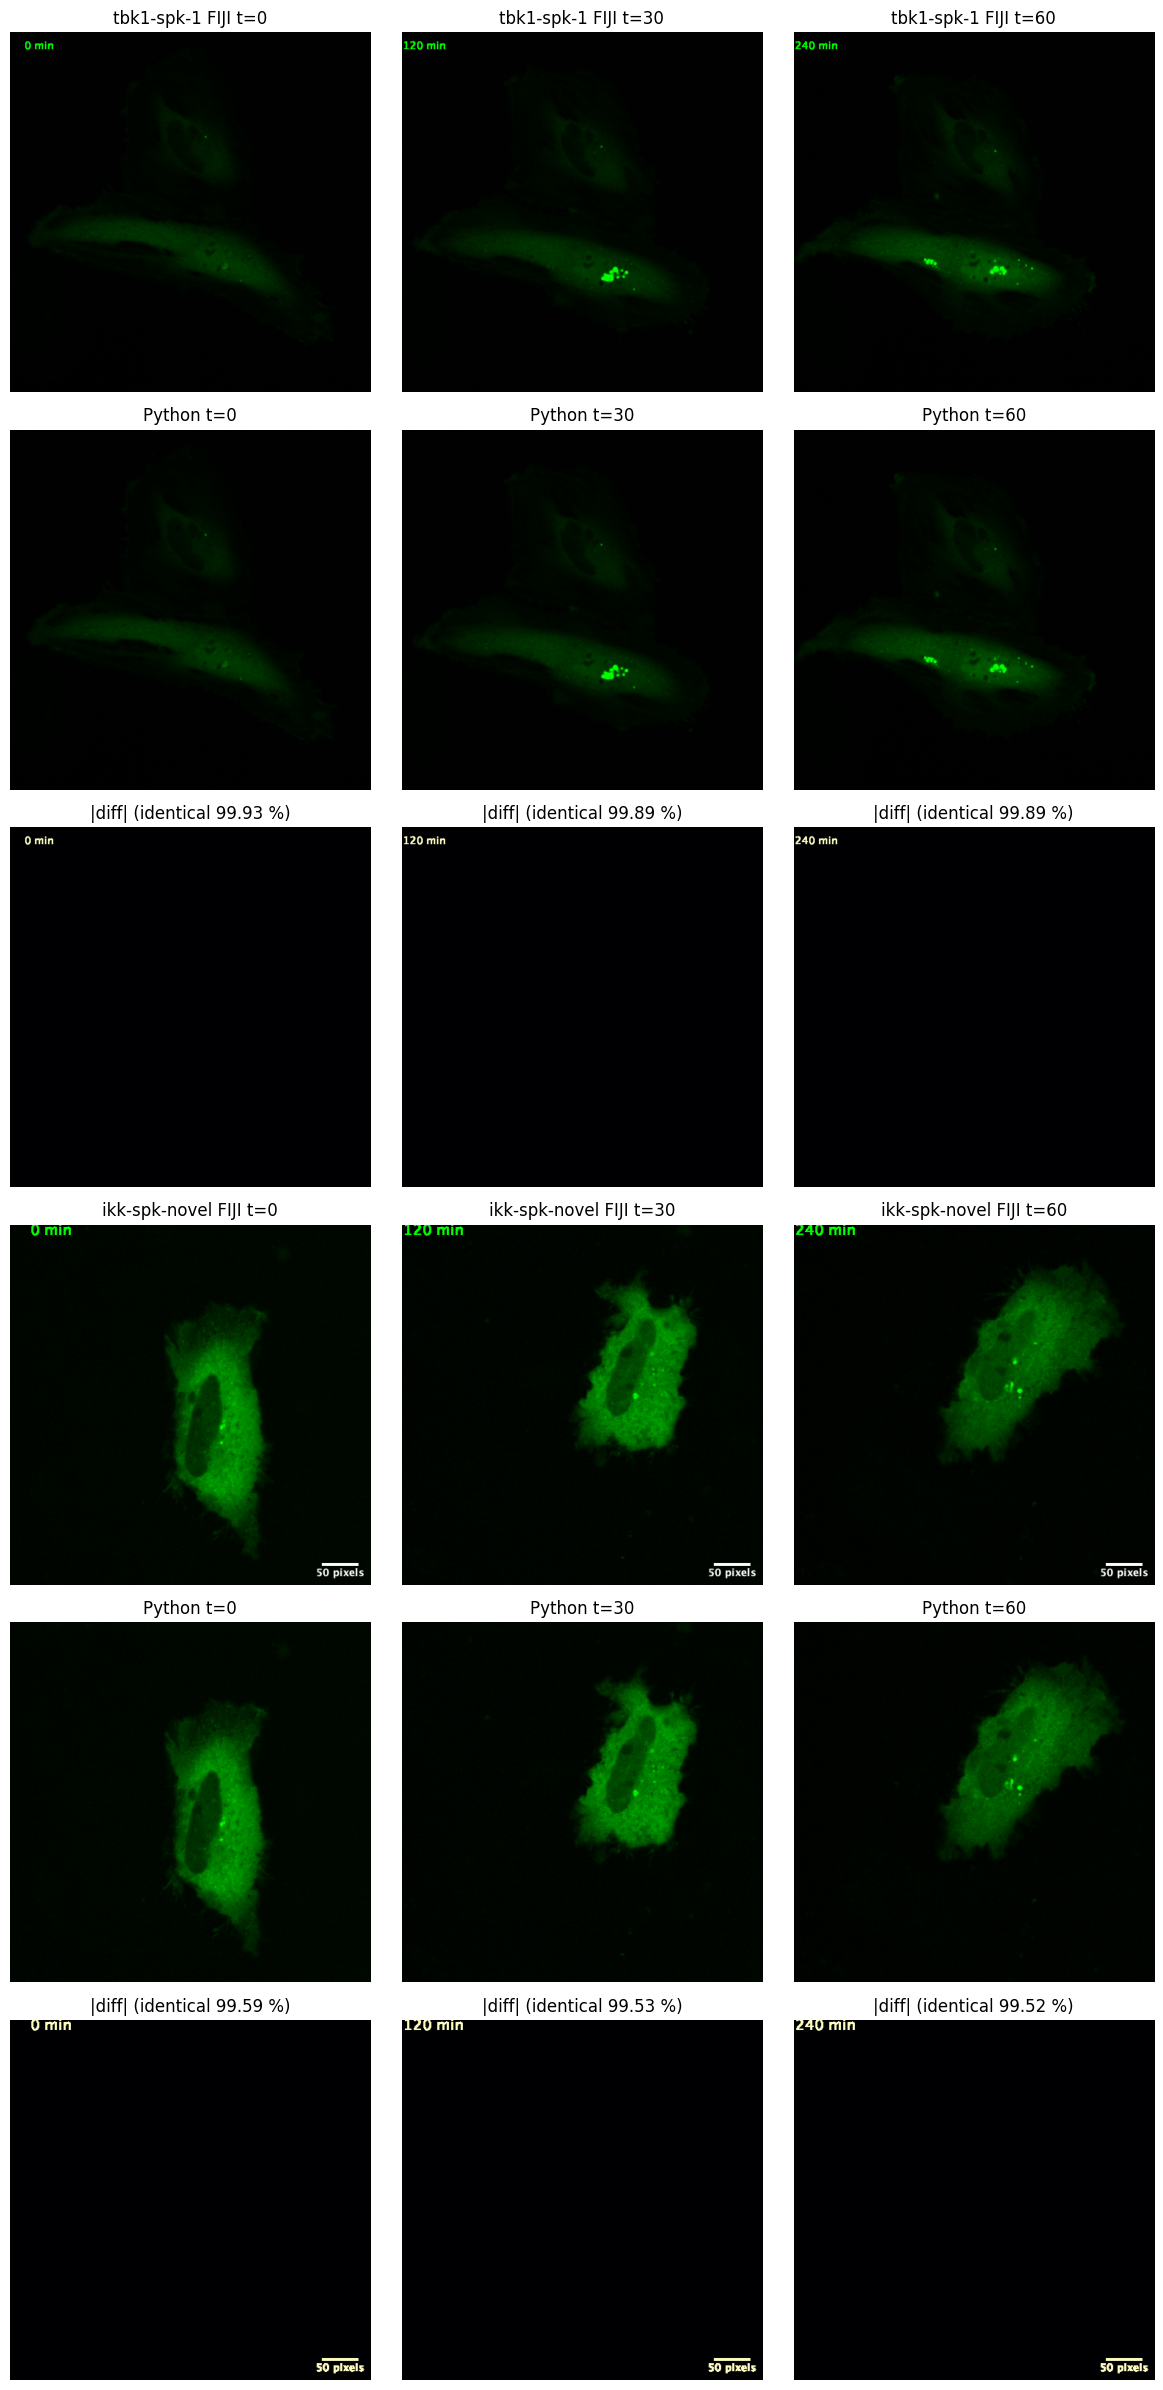

In [9]:
# Side-by-side: FIJI export vs Python re-creation vs |difference|
frames = [0, 30, 60]
fig, axes = plt.subplots(len(stacks) * 3, len(frames), figsize=(4 * len(frames), 4 * 3 * len(stacks)))
for i, (name, stack) in enumerate(stacks.items()):
    rgb = normalize_like_fiji(stack, params[name]); files = png_files(name)
    for j, t in enumerate(frames):
        fiji = np.array(Image.open(files[t]).convert('RGB'))
        diff = np.abs(fiji[..., 1].astype(int) - rgb[t][..., 1].astype(int))
        axes[3*i, j].imshow(fiji); axes[3*i, j].set_title(f'{name} FIJI t={t}')
        axes[3*i+1, j].imshow(rgb[t]); axes[3*i+1, j].set_title(f'Python t={t}')
        axes[3*i+2, j].imshow(diff, cmap='magma', vmin=0, vmax=5)
        axes[3*i+2, j].set_title(f'|diff| (identical {np.mean(diff == 0)*100:.2f} %)')
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## D. `ikk-spk-1` ← `20240822_cy_plate2c1xy13.tif`

Source identified from the 240822 plate2 hit list (row C, IKK-SPK-1, TNFa, xy13). The raw tif lives only at
`${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy13.tif`; copy it next to this notebook
(or run where `${SPARK_ACQUISITION_MOUNT}` is mounted). Frames are 432×433 with a **Grays** LUT and `frame_0001.png` = raw frame 0.
Crop = (x 128, y 1176, w 433, h 432). Unlike the other examples, the display range is **piecewise constant over time** — a single (min, max) only fits frames 0–27, so the range is fitted per frame and grouped into blocks.

In [10]:
src = next((c for c in ['20240822_cy_plate2c1xy13.tif',
                          '${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20240822_cy_plate2/20240822_cy_plate2c1xy13.tif'] if os.path.exists(c)))
raw_xy13 = tifffile.imread(src)
files = png_files('ikk-spk-1'); png0 = load_png_value(files[0]); h, w = png0.shape
x, y, cc = locate_crop(raw_xy13[30], load_png_value(files[30]))
print(src, raw_xy13.shape, raw_xy13.dtype, f'crop x={x} y={y} w={w} h={h} (cc on frame 30 = {cc:.3f})')

def exact_range(crop, png, mn0, mx0, dmn=30, dmx=400):
    """Exhaustive (min, max) search using a raw-value x png-value joint histogram (fast)."""
    c = crop.astype(np.int64).ravel(); p = png.astype(np.int64).ravel()
    u, inv = np.unique(c, return_inverse=True)
    J = np.zeros((len(u), 256), np.int64); np.add.at(J, (inv, p), 1)
    acc = lambda a, b: J[np.arange(len(u)), ij_to_8bit(u, a, b)].sum() / c.size
    _, a1, b1 = max((acc(a, b), a, b) for a in range(int(mn0)-dmn, int(mn0)+dmn+1, 3) for b in range(int(mx0)-dmx, int(mx0)+dmx+1, 10))
    return max((acc(a, b), a, b) for a in range(a1-4, a1+5) for b in range(b1-15, b1+16))

per_frame = []
for t in range(len(files)):
    crop = raw_xy13[t, y:y+h, x:x+w]; png = load_png_value(files[t])
    m = (png > 0) & (png < 250); a, b = np.polyfit(crop[m].astype(float), png[m].astype(float), 1)
    acc, mn, mx = exact_range(crop, png, -b/a, -b/a + 256/a - 1)
    per_frame.append((t, mn, mx, acc))
pf = pd.DataFrame(per_frame, columns=['frame', 'min', 'max', 'identical'])
blocks = pf.groupby(['min', 'max'], sort=False)['frame'].agg(['min', 'max']).rename(columns={'min': 'first_frame', 'max': 'last_frame'}).reset_index()
print(blocks.to_string(index=False))
print(f"identical pixels per frame: {pf.identical.min()*100:.2f}–{pf.identical.max()*100:.2f} %")


20240822_cy_plate2c1xy13.tif (61, 1608, 1608) uint16 crop x=128 y=1176 w=433 h=432 (cc on frame 30 = 0.908)


 min  max  first_frame  last_frame
 119 2639            0          27
 115 4403           28          34
 117 7328           35          42
 116 9546           43          60
identical pixels per frame: 99.42–99.51 %


max 2639: equals crop max of frame(s) [np.int64(19)]
max 4403: equals crop max of frame(s) [np.int64(27)]
max 7328: equals crop max of frame(s) [np.int64(36)]
max 9546: equals crop max of frame(s) [np.int64(56)]


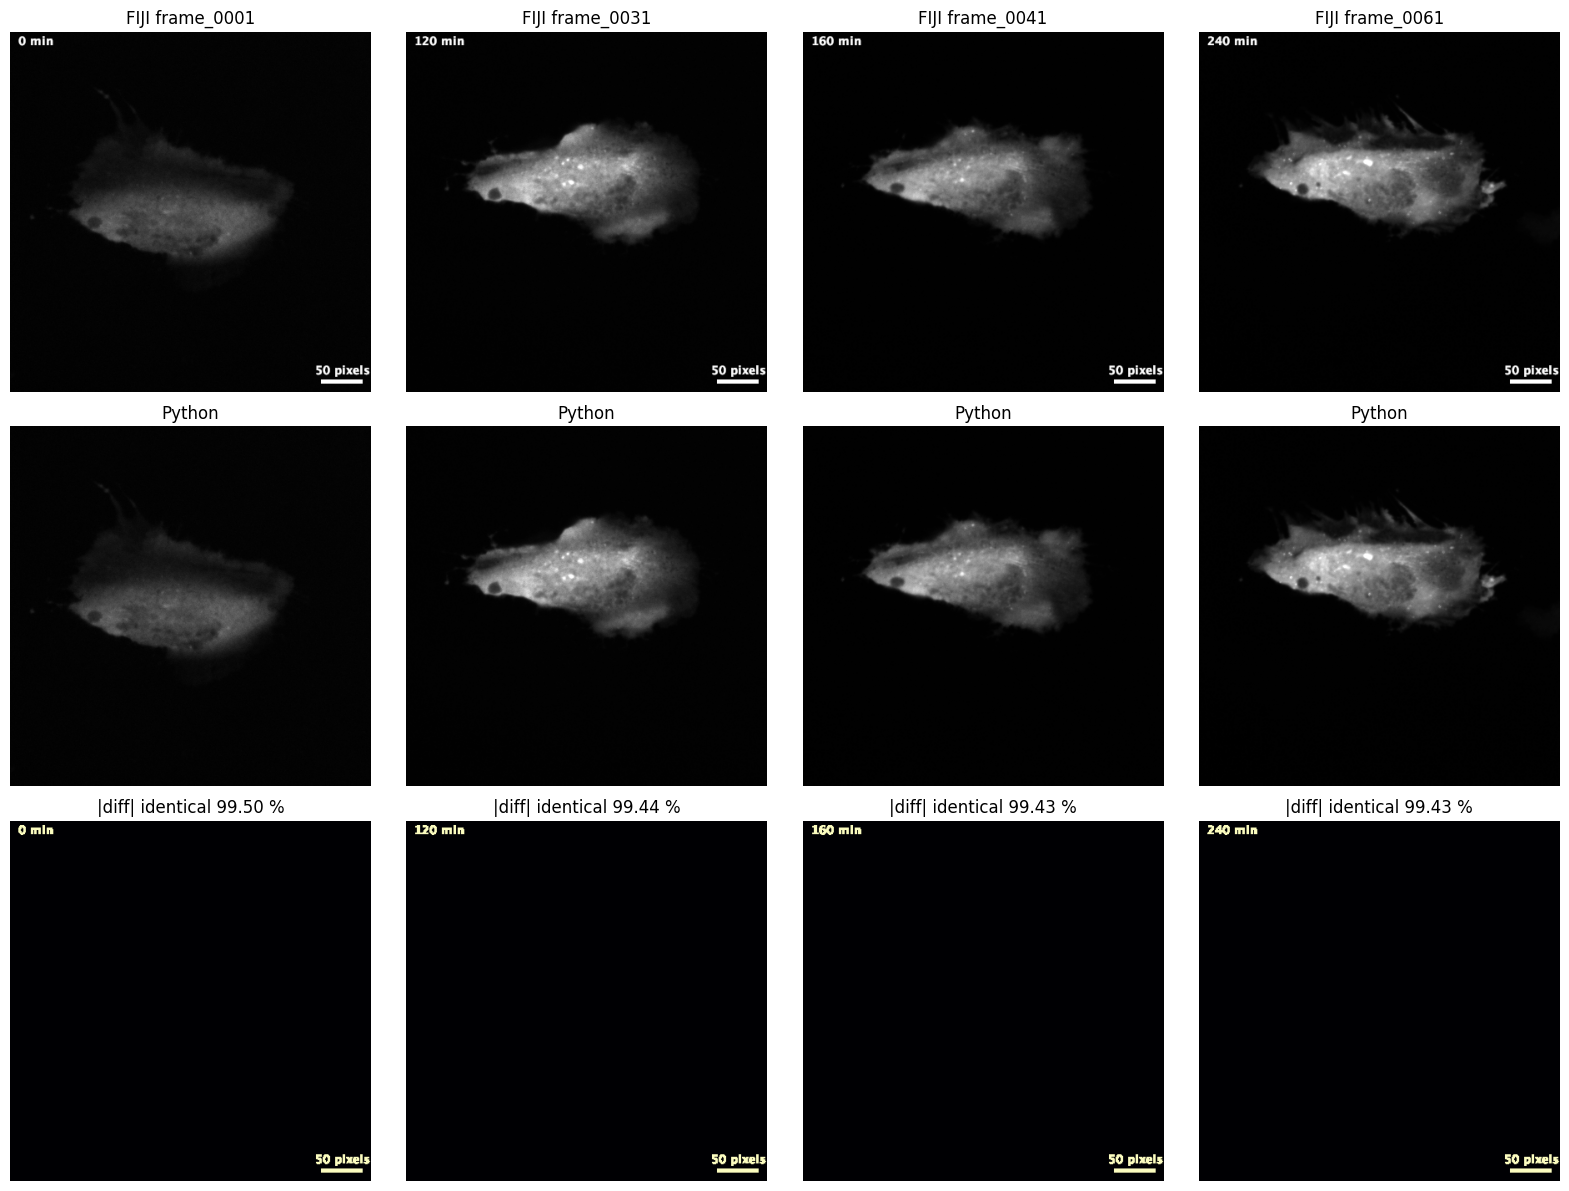

In [11]:
# brighest crop pixel per frame — the new max values coincide with these (FIJI B&C 'Set'/auto on the current slice)
crop_max = raw_xy13[:, y:y+h, x:x+w].reshape(len(files), -1).max(1)
for _, r in blocks.iterrows():
    hits = np.where(crop_max == r['max'])[0]
    print(f"max {r['max']}: equals crop max of frame(s) {list(hits)}")

params['ikk-spk-1'] = dict(x=x, y=y, w=w, h=h, frame_ranges=[(int(r.first_frame), int(r.last_frame), int(r['min']), int(r['max'])) for _, r in blocks.iterrows()])
img8 = np.zeros((len(files), h, w), np.uint8)
for f0, f1, mn, mx in params['ikk-spk-1']['frame_ranges']:
    img8[f0:f1+1] = ij_to_8bit(raw_xy13[f0:f1+1, y:y+h, x:x+w], mn, mx)
out = os.path.join('python_normalized', 'ikk-spk-1'); os.makedirs(out, exist_ok=True)
for t, fr in enumerate(img8):
    Image.fromarray(fr).save(os.path.join(out, f'ikk-spk-1_{t+1:04d}.png'))

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for j, t in enumerate([0, 30, 40, 60]):
    fiji = load_png_value(files[t]); d = np.abs(fiji.astype(int) - img8[t].astype(int))
    axes[0, j].imshow(fiji, cmap='gray', vmin=0, vmax=255); axes[0, j].set_title(f'FIJI frame_{t+1:04d}')
    axes[1, j].imshow(img8[t], cmap='gray', vmin=0, vmax=255); axes[1, j].set_title('Python')
    axes[2, j].imshow(d, cmap='magma', vmin=0, vmax=5); axes[2, j].set_title(f'|diff| identical {np.mean(d == 0)*100:.2f} %')
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

### FIJI equivalent (to redo by hand)
```
open raw tif → makeRectangle(x, y, w, h) → Image ▸ Crop
Image ▸ Adjust ▸ Brightness/Contrast ▸ Set: min, max (apply to all slices not needed; display range is per stack)
Image ▸ Lookup Tables ▸ Green
Image ▸ Type ▸ 8-bit   (or RGB Color) → File ▸ Save As ▸ Image Sequence (PNG)
```
e.g. `tbk1-spk-1`: `makeRectangle(396, 806, 694, 694); setMinAndMax(119, 7152);` — `ikk-spk-novel`: `makeRectangle(442, 578, 492, 492); setMinAndMax(137, 1150);`